### Exploratory Data Analysis and Statistics

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy as stats

print('Libraries are ready')

Libraries are ready


In [5]:
gap_df = pd.read_csv('inequality_gap_sex.csv')
print(gap_df['inequality_gap'].describe())
print('\nSkewness:',gap_df['inequality_gap'].skew())

count     79448.000000
mean        -15.210221
std         978.883824
min     -188612.960000
25%          -3.200000
50%          -0.440845
75%           0.786525
max       26042.530000
Name: inequality_gap, dtype: float64

Skewness: -177.95456257730672


The 25th to 75th percentile range is just -3.2 to 0.79, tight and reasonable. But the minimum is -188,612 and the maximum is 26,042. Something is producing a small number of enormous values that don't belong on the same scale as the rest of the data. This gap between "what most of the data looks like" and "what the extremes look like" is exactly what a skewness of -177.95 is picking up on.

#### Investigating Which Rows Are Causing This?

In [6]:
print(gap_df.nsmallest(3, 'inequality_gap')[
    ['setting','date','indicator_name','female_estimate','male_estimate','inequality_gap']])

       setting  date                                     indicator_name  \
25354  Finland  2010  8.8.1 Non-fatal occupational injuries among em...   
25316  Finland  2009  8.8.1 Non-fatal occupational injuries among em...   
13031   Canada  2016  2.3.2 Average income of large-scale food produ...   

       female_estimate  male_estimate  inequality_gap  
25354        135339.25      323952.21      -188612.96  
25316        127932.71      313992.81      -186060.10  
13031         42393.25       85122.26       -42729.01  


In [18]:
df_full = pd.read_csv('who_data_cleaned.csv')

merged_scale = gap_df.merge(df_full[['indicator_abbr','indicator_scale']].drop_duplicates(),
    on='indicator_abbr', how='left')
print(merged_scale.groupby('indicator_scale')['inequality_gap'].describe()[['count','mean','50%','max']])

                   count        mean      50%          max
indicator_scale                                           
2                 2973.0   -0.046449  -0.0141      1.72222
100              56482.0    0.927073  -0.1000    100.00000
1000             12845.0   -3.903222  -1.9000      9.70000
10000              249.0 -253.225301 -87.0300    206.78000
100000            6899.0 -166.322142  -2.6600  26042.53000


#### Histogram and Boxplot (Documenting the Skew Honesty)


Rows in the middle 98%: 77861 (98.0%)

Skewness of this trimmed view: -0.7797879774916431


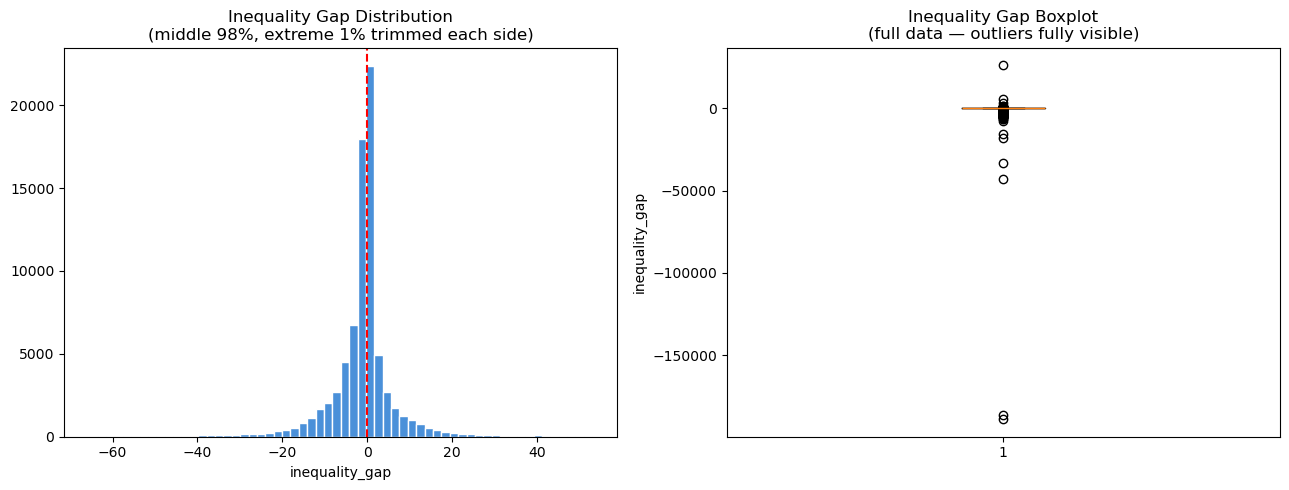

In [22]:
import os

os.makedirs('images', exist_ok=True)

p01 = gap_df['inequality_gap'].quantile(0.01)
p99 = gap_df['inequality_gap'].quantile(0.99)
trimmed = gap_df[(gap_df['inequality_gap'] >= p01) & (gap_df['inequality_gap'] <= p99)]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].hist(trimmed['inequality_gap'], bins=60, color='#4A90D9', edgecolor='white')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_title('Inequality Gap Distribution\n(middle 98%, extreme 1% trimmed each side)')
axes[0].set_xlabel('inequality_gap')

axes[1].boxplot(gap_df['inequality_gap'], vert=True)
axes[1].set_title('Inequality Gap Boxplot\n(full data — outliers fully visible)')
axes[1].set_ylabel('inequality_gap')

print(f"\nRows in the middle 98%: {len(trimmed)} ({len(trimmed)/len(gap_df)*100:.1f}%)")
print("\nSkewness of this trimmed view:", trimmed['inequality_gap'].skew())

plt.tight_layout()
plt.savefig('images/04_distribution.png', dpi=150)
plt.show()

#### Direction of the gap (Negative vs Positive vs Zero)

Negative\n(Female < Male)    49144
Positive\n(Female > Male)    27085
Zero                          3219
dtype: int64


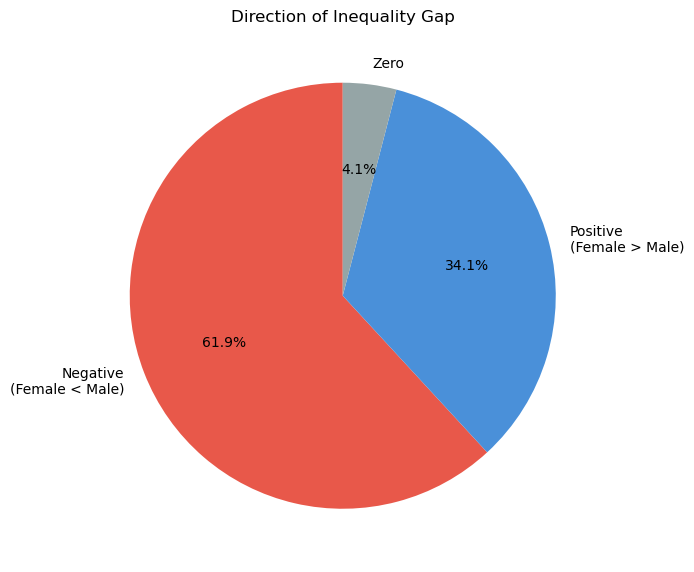

In [23]:
sign_counts = pd.Series({
    'Negative\n(Female < Male)': (gap_df['inequality_gap'] < 0).sum(),
    'Positive\n(Female > Male)': (gap_df['inequality_gap'] > 0).sum(),
    'Zero': (gap_df['inequality_gap'] == 0).sum(),
})
print(sign_counts)

fig, ax = plt.subplots(figsize=(7, 7))
ax.pie(sign_counts, labels=sign_counts.index, autopct='%1.1f%%',
       colors=['#E8584A', '#4A90D9', '#95A5A6'], startangle=90)
ax.set_title('Direction of Inequality Gap')
plt.tight_layout()
plt.savefig('images/04_sign_pie.png', dpi=150)
plt.show()

Nearly 62% of all validated observations show Female estimates lower than Male estimates. 

#### Trend Overtime 

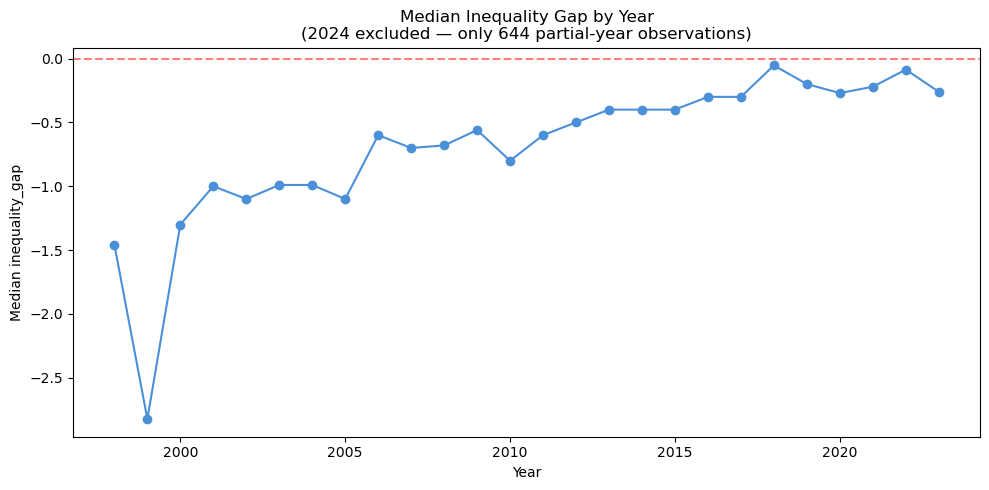

In [24]:
yearly = gap_df[gap_df['date'] < 2024].groupby('date')['inequality_gap'].median()

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(yearly.index, yearly.values, marker='o', color='#4A90D9')
ax.axhline(0, color='red', linestyle='--', alpha=0.5)
ax.set_title('Median Inequality Gap by Year\n(2024 excluded — only 644 partial-year observations)')
ax.set_xlabel('Year')
ax.set_ylabel('Median inequality_gap')
plt.tight_layout()
plt.savefig('images/04_year_trend.png', dpi=150)
plt.show()

The finding here is genuinely encouraging: the median gap has moved from roughly -1.5 in 1998 to close to -0.25 by 2023 — steadily approaching zero. This is real evidence that, across the indicators in this dataset, the Male/Female disparity has been narrowing over the past two decades.

#### Gap by Country (Mean vs Median)

In [25]:
country_stats_mean = gap_df.groupby('setting')['inequality_gap'].agg(
    avg_abs_gap=lambda x: x.abs().mean(), count='count')
country_stats_mean = country_stats_mean[country_stats_mean['count'] >= 20].sort_values('avg_abs_gap', ascending=False)
print("=== Top 5 by MEAN absolute gap ===")
print(country_stats_mean.head(5))

country_stats_median = gap_df.groupby('setting')['inequality_gap'].agg(
    median_abs_gap=lambda x: x.abs().median(), count='count')
country_stats_median = country_stats_median[country_stats_median['count'] >= 20].sort_values('median_abs_gap', ascending=False)
print()
print("=== Top 5 by MEDIAN absolute gap ===")
print(country_stats_median.head(5))

=== Top 5 by MEAN absolute gap ===
                  avg_abs_gap  count
setting                             
Finland            493.832697    820
Canada             262.463522    480
Marshall Islands   180.014402    151
Spain               91.167366    892
Argentina           79.372774    526

=== Top 5 by MEDIAN absolute gap ===
                                  median_abs_gap  count
setting                                                
Tokelau                                    30.00     23
Micronesia (Federated States of)            7.00    109
Niue                                        6.70     75
Eritrea                                     5.80    222
Central African Republic                    5.08    166


Ranking countries in two different ways by mean absolute gap, and separately by median absolute gap using only countries with at least 20 observations so a country with just 2-3 data points can't dominate the ranking by chance.

The mean based ranking is topped by Finland and Canada but we already know from Cells 3–4 exactly why: because both countries happen to have data for the per 100,000 scale occupational injury indicator, which inflates their mean absolute gap even though their typical (median) gap is unremarkable. The median-based ranking tells a completely different, more honest story the small island nations and lower resource countries such as (Tokelau, Micronesia, Niue) show the largest typical disparities.

#### Finding the Gap by WHO Region and Income Group

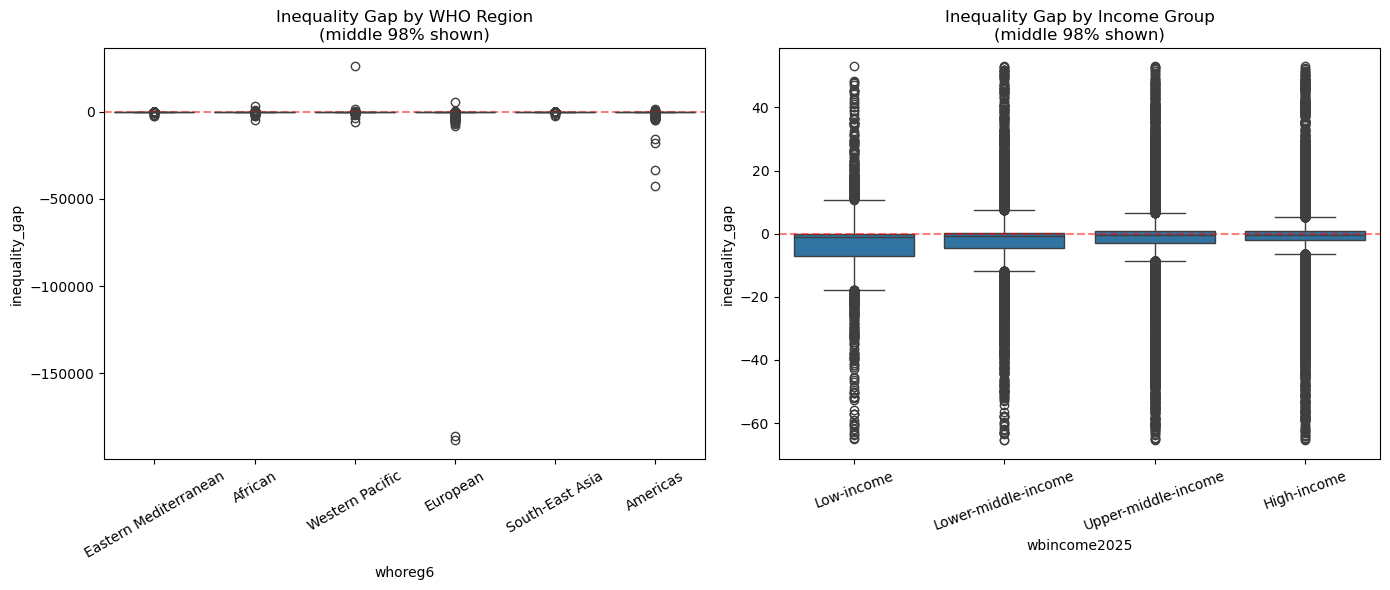

                     median_gap  median_abs_gap  count
wbincome2025                                          
Low-income            -0.900000            3.50   6519
Lower-middle-income   -0.551125            2.40  16106
Upper-middle-income   -0.500000            2.20  21951
High-income           -0.300000            1.54  34080


In [28]:
if 'whoreg6' not in gap_df.columns:
    try:
        df_full = pd.read_csv('who_data_cleaned.csv')
    except Exception:
        df_full = pd.read_excel('WHO Dataset.xlsx', sheet_name='Data')
    region_map = df_full[['iso3', 'whoreg6']].drop_duplicates('iso3')
    gap_df_region = gap_df.merge(region_map, on='iso3', how='left')
else:
    gap_df_region = gap_df.copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

region_order = (
    gap_df_region.groupby('whoreg6')['inequality_gap']
    .median()
    .sort_values()
    .index)

sns.boxplot(data=gap_df_region,x='whoreg6',y='inequality_gap',order=region_order,ax=axes[0])

axes[0].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[0].set_title('Inequality Gap by WHO Region\n(middle 98% shown)')
axes[0].tick_params(axis='x', rotation=30)

income_order = ['Low-income','Lower-middle-income','Upper-middle-income','High-income']

sns.boxplot(data=trimmed,x='wbincome2025',y='inequality_gap',order=income_order,ax=axes[1])

axes[1].axhline(0, color='red', linestyle='--', alpha=0.5)
axes[1].set_title('Inequality Gap by Income Group\n(middle 98% shown)')
axes[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('images/04_region_income.png', dpi=150)
plt.show()

print(gap_df.groupby('wbincome2025')['inequality_gap'].agg(median_gap='median',median_abs_gap=lambda x: x.abs().median(),count='count').reindex(income_order))

It compares the gap distribution across WHO's 6 regions and across the 4 World Bank income tiers, using the same trimmed 98% view established in Cell 5 for readability, plus an exact summary table using medians.

There's a clean, interpretable pattern in the table median absolute gap decreases steadily as income rises : 3.50 for Low-income countries down to 1.54 for High-income countries. In this dataset, wealthier countries tend to show smaller Male/Female disparities across health-related indicators than lower-income countries.

#### Finding Gaps by Indicator

In [31]:
ind_stats = gap_df.groupby('indicator_name')['inequality_gap'].agg(
    median_abs_gap=lambda x: x.abs().median(), count='count')
ind_stats = ind_stats[ind_stats['count'] >= 30].sort_values('median_abs_gap', ascending=False)

print("\n=== Top 5 indicators by median absolute gap ===")
print(ind_stats.head(5))
print("\n=== Bottom 5 (smallest, most equal indicators) ===")
print(ind_stats.tail(5))


=== Top 5 indicators by median absolute gap ===
                                                    median_abs_gap  count
indicator_name                                                           
2.3.2 Average income of large-scale food produc...        1005.565    100
2.3.2 Average income of small-scale food produc...         462.560     99
8.8.1 Non-fatal occupational injuries among emp...         391.825    626
3.c.1 Health worker distribution (%) - Nurses               71.800    811
2.3.1 Productivity of large-scale food producer...          39.040    150

=== Bottom 5 (smallest, most equal indicators) ===
                                                    median_abs_gap  count
indicator_name                                                           
1.3.1 Unemployed persons receiving unemployment...             0.0    399
1.3.1 Population with severe disabilities recei...             0.0    250
1.3.1 Vulnerable population receiving social as...             0.0     68
1.3.1 Popul

The top of the list is dominated by income and occupational safety indicators — real, substantial gender gaps in the labor market. 
The bottom of the list is striking in a different way: several social protection and pension indicators show a median gap of exactly zero which means Male and Female populations are receiving these benefits at genuinely equal rates.

#### Finding is the Gap Normally Distributed?

In [35]:
from scipy import stats
sample = gap_df['inequality_gap'].sample(min(5000, len(gap_df)), random_state=42)
stat, p_value = stats.shapiro(sample)

print(f"Shapiro-Wilk statistic: {stat:.6f}")
print(f"\nP-value: {p_value:.10f}")
print("\nNormally distributed?", "Yes" if p_value > 0.05 else "No reject normality")

Shapiro-Wilk statistic: 0.098068

P-value: 0.0000000000

Normally distributed? No reject normality


=====================================================================================================================================================
The Shapiro-Wilk test, which checks whether a sample plausibly comes from a normal bell-curve distribution. 
It's run on a random sample of 5,000 rather than the full 79,448 because Shapiro-Wilk becomes overly sensitive on very large samples

The result is unambiguous a p-value far below 0.05 means we confidently reject the idea that inequality_gap is normally distributed. This one test result is what justifies every remaining statistical choice in this module.Given Cells 2–4 already showed us this distribution has extreme outliers, this result is not surprising, but confirming it formally, rather than assuming it.

#### Mann-Whitney U (Two-Group Comparison)

In [36]:
high = gap_df[gap_df['wbincome2025'] == 'High-income']['inequality_gap'].dropna()
low = gap_df[gap_df['wbincome2025'] == 'Low-income']['inequality_gap'].dropna()

stat, p_value = stats.mannwhitneyu(high, low, alternative='two-sided')
print(f"High-income n={len(high)}, Low-income n={len(low)}")
print(f"U statistic: {stat:.2f}")
print(f"P-value: {p_value:.6f}")
print("Statistically significant difference?", "Yes" if p_value < 0.05 else "No")

High-income n=34080, Low-income n=6519
U statistic: 134047722.00
P-value: 0.000000
Statistically significant difference? Yes


Compares the gap distribution between High-income and Low-income countries specifically two groups, non-parametric test.

The reason to do this test instead of t-test a t-test compares group means, and assumes normality both are problematic given Cell 11's result. Mann Whitney U instead compares whether one group's values tend to rank higher or lower than the other's, without assuming any particular distribution shape. 
The result confirms what Cell 9's table already suggested the difference between High-income and Low-income countries' gap patterns is statistically significant, not just a small, possibly-random difference in the sample.

In [38]:
abs_gap = gap_df['inequality_gap'].abs()
low_cut = abs_gap.quantile(1/3)
med_cut = abs_gap.quantile(2/3)

print(f"Low upper bound (33rd percentile):    {low_cut:.2f}")
print(f"Medium upper bound (66th percentile): {med_cut:.2f}")
print()
print(f"Low risk:    |gap| <= {low_cut:.2f}")
print(f"Medium risk: {low_cut:.2f} < |gap| <= {med_cut:.2f}")
print(f"High risk:   |gap| > {med_cut:.2f}")

Low upper bound (33rd percentile):    0.90
Medium upper bound (66th percentile): 4.20

Low risk:    |gap| <= 0.90
Medium risk: 0.90 < |gap| <= 4.20
High risk:   |gap| > 4.20


Calculates the exact percentile cutoffs that split abs inequality_gap  into three equally-sized groups.

In [40]:
from IPython.display import display, Markdown

summary = """
## Module 4 Summary

| **Finding** | **Result** |
|---|---|
| Raw skewness of `inequality_gap` | -177.95 (extreme) |
| Root cause | 5 different `indicator_scale` values mixed in one column |
| Skewness after trimming top/bottom 1% | -0.78 (reasonable) |
| Negative gaps | 61.9% |
| Positive gaps | 34.1% |
| Zero gaps | 4.1% |
| Trend over time | Narrowing — median gap moved from ~-1.5 (1998) to ~-0.25 (2023) |
| Largest typical gaps (by median) | Tokelau, Micronesia, Niue |
| Largest typical gaps (by indicator) | Food producer income, occupational injuries, nurse distribution |
| Smallest gaps (by indicator) | Several social protection/pension indicators — exactly 0 |
| Income pattern | Median absolute gap falls steadily as income rises (3.50 → 1.54) |
| Shapiro-Wilk normality test | **Rejected** (p < 0.0001) |
| Mann-Whitney U (High vs Low income) | Significant (p < 0.0001) |
| Tercile thresholds for Module 6 | Low ≤ 0.90, Medium ≤ 4.20, High > 4.20 |
"""

display(Markdown(summary))


## Module 4 Summary

| **Finding** | **Result** |
|---|---|
| Raw skewness of `inequality_gap` | -177.95 (extreme) |
| Root cause | 5 different `indicator_scale` values mixed in one column |
| Skewness after trimming top/bottom 1% | -0.78 (reasonable) |
| Negative gaps | 61.9% |
| Positive gaps | 34.1% |
| Zero gaps | 4.1% |
| Trend over time | Narrowing — median gap moved from ~-1.5 (1998) to ~-0.25 (2023) |
| Largest typical gaps (by median) | Tokelau, Micronesia, Niue |
| Largest typical gaps (by indicator) | Food producer income, occupational injuries, nurse distribution |
| Smallest gaps (by indicator) | Several social protection/pension indicators — exactly 0 |
| Income pattern | Median absolute gap falls steadily as income rises (3.50 → 1.54) |
| Shapiro-Wilk normality test | **Rejected** (p < 0.0001) |
| Mann-Whitney U (High vs Low income) | Significant (p < 0.0001) |
| Tercile thresholds for Module 6 | Low ≤ 0.90, Medium ≤ 4.20, High > 4.20 |
